In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
#plt.rcParams['axes.grid'] = True

In [2]:
r_tube = 3.34e-3
L_tube = 640.0e-3

stopper_depth = 11.94e-3
stopper_depth_err = 0.10e-3

h_can = 111.26e-3
r_can = 46.28e-3 / 2

r_chamber = 39.30e-3 / 2

chamberless_volume = np.pi * (r_tube**2 * L_tube + (h_can - stopper_depth) * r_can**2)

g = 9.80

atm = 101325 # 1 atm in pascals

k_B = 1.380649e-23


In [3]:
cold_temps_100g = np.array([16.675, 18.037, 18.894, 19.575])
cold_temps_100g_err = np.array([0.019, 0.038, 0.038, 0.047])

cold_heights_100g = np.array([24.0, 19.4, 15.0, 12.0]) * 1e-3
cold_heights_100g_err = np.ones(len(cold_heights_100g)) * 0.5e-3
cold_heights_mass_100g = np.array([21.5, 16.1, 12.1, 9.1]) * 1e-3
cold_heights_mass_100g_err = np.ones(len(cold_heights_mass_100g)) * 0.5e-3

hot_temps_100g = np.array([46.043, 44.254, 41.731, 40.768])
hot_temps_100g_err = np.array([0.017, 0.014, 0.127, 0.013])

hot_heights_mass_100g = np.array([35.2, 28.3, 22.9, 18.5]) * 1e-3
hot_heights_mass_100g_err = np.ones(len(hot_heights_mass_100g)) * 0.5 * 1e-3
hot_heights_100g = np.array([34.5, 29.0, 24.8, 20.6]) * 1e-3
hot_heights_100g_err = np.ones(len(hot_heights_100g)) * 0.5 * 1e-3



In [ ]:
masses = np.array([100])
cold_temps = np.array([cold_temps_100g])
cold_temps_err = np.array([cold_temps_100g_err])
cold_heights = np.array([cold_heights_100g])
cold_heights_mass = np.array([cold_heights_mass_100g])
hot_temps = np.array([hot_temps_100g])
hot_temps_err = np.array([hot_temps_100g_err])
hot_heights = np.array([hot_heights_100g])
hot_heights_err = np.array([hot_heights_100g_err])
hot_heights_mass = np.array([hot_heights_mass_100g])
hot_heights_mass_err = np.array([hot_heights_mass_100g_err])

cold_volumes = chamberless_volume + np.pi * r_chamber**2 * np.array([cold_heights])
hot_volumes = chamberless_volume + np.pi * r_chamber**2 * np.array([hot_heights])
cold_volumes_mass = chamberless_volume + np.pi * r_chamber**2 * np.array([cold_heights_mass])
hot_volumes_mass = chamberless_volume + np.pi * r_chamber**2 * np.array([hot_heights_mass])


low_pressures = atm * np.ones(len(masses))
high_pressures = atm + (masses * g) / (np.pi * r_chamber**2)

In [ ]:
work_by_gas = 0.5 * (low_pressures + high_pressures) * (cold_volumes_mass - cold_volumes)

In [5]:
for i in range(len(masses)):
    #print(high_pressures[i] * hot_volumes_mass[i] / (k_B * hot_temps[i]))
    print(masses[i] * (cold_heights_mass[i] - cold_heights[i]))
    print(0.5 * (low_pressures[i] + high_pressures[i]) * (cold_volumes_mass[i] - cold_volumes[i]))

[-0.25 -0.33 -0.29 -0.29]
[[-1.5322781  -2.02260709 -1.77744259 -1.77744259]]


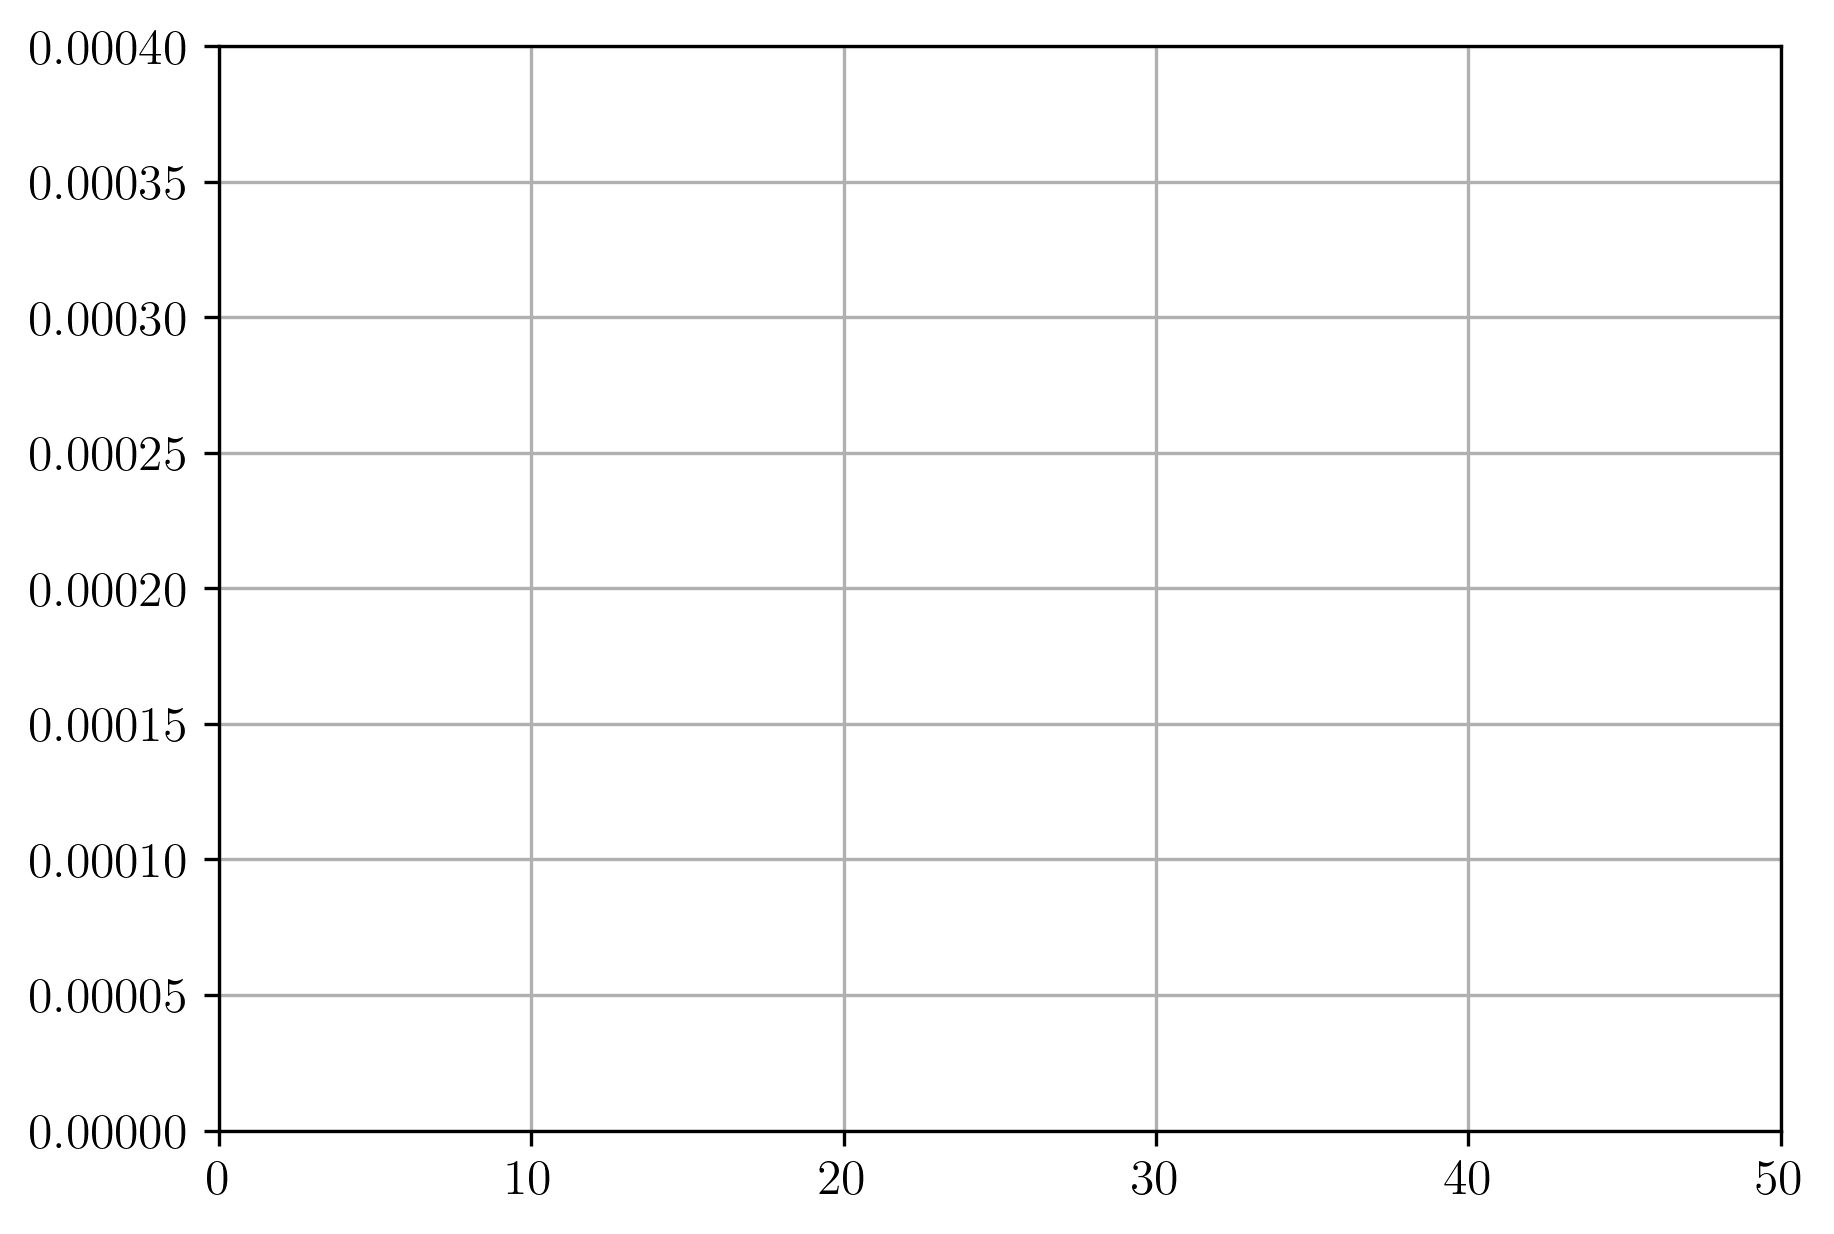

In [6]:
fig, ax = plt.subplots(1, figsize=(6, 4), layout="constrained")


#ax.scatter(temps, volumes)

ax.set_ylim(0, 0.0004)
ax.set_xlim(0, 50)

ax.grid()